# Trabajo Práctico 3 (TP3): Clasificación de Imágenes de Cáncer de Mama usando PCA y SVD

## Objetivo
El objetivo de este Trabajo Práctico es aplicar los conceptos de reducción de dimensionalidad vistos en la Clase 8 (**SVD y PCA**) para construir un clasificador de imágenes médicas. 

Trabajaremos con imágenes de ultrasonido de mama para clasificarlas en **Benignas** o **Malignas**.

## 1. Obtención del Dataset (BreastMNIST)
Para este TP utilizaremos **BreastMNIST**, un subconjunto del famoso dataset MedMNIST, el cual contiene imágenes de ultrasonido de mama de 28x28 píxeles en escala de grises.

**Instrucciones:** Si no tienes instalada la librería `medmnist`, ejecuta la siguiente celda.

In [1]:
# !pip install medmnist

A continuación, descargaremos y cargaremos los datos de entrenamiento y prueba.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import medmnist
from medmnist import BreastMNIST

# Descargar y cargar los datos
train_dataset = BreastMNIST(split='train', download=True)
test_dataset = BreastMNIST(split='test', download=True)

# Extraer las imágenes y las etiquetas
X_train = train_dataset.imgs
y_train = train_dataset.labels.squeeze()

X_test = test_dataset.imgs
y_test = test_dataset.labels.squeeze()

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (546, 28, 28)
Dimensiones de X_test: (156, 28, 28)


### Configuración adicional y revisión de las etiquetas *(celda agregada)*

Antes de seguir conviene mirar qué significa cada etiqueta según la propia librería (`train_dataset.info['label']`). En BreastMNIST, **la etiqueta 0 es `malignant` y la 1 es `normal, benign`**: MedMNIST junta las imágenes normales y benignas en una sola clase. Es lo opuesto a lo que supone la Consigna 1 ("benignos (etiqueta 0)"). Para no depender de esa suposición, el resto del cuaderno toma los nombres y el índice de la clase maligna directamente de `info`.

Además, la **clase positiva** de las métricas (F1, Curva ROC) será **maligno**: es la que interesa detectar.

In [3]:
import time
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

# Configuración visual (misma que la práctica C8)
plt.rcParams.update({
    'figure.figsize': (8, 5),
    'axes.grid': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 12
})
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Significado de las etiquetas según MedMNIST
etiquetas_info = {int(k): v for k, v in train_dataset.info['label'].items()}
IDX_MAL = next(k for k, v in etiquetas_info.items() if v == 'malignant')   # índice de la clase maligna
IDX_NOMAL = 1 - IDX_MAL
NOMBRES = {IDX_MAL: 'Maligno', IDX_NOMAL: 'Normal/Benigno'}
print('Etiquetas según MedMNIST:', etiquetas_info)
print(f'→ clase maligna = {IDX_MAL}  |  clase normal/benigna = {IDX_NOMAL}')

# Distribución por partición (MedMNIST trae una partición oficial 7:1:2)
val_dataset = BreastMNIST(split='val', download=True)       # solo para mostrar la partición completa
y_val = val_dataset.labels.squeeze()
tabla = pd.DataFrame({nombre: [np.sum(yy == IDX_MAL), np.sum(yy == IDX_NOMAL), len(yy)]
                      for nombre, yy in [('train', y_train), ('val', y_val), ('test', y_test)]},
                     index=['Maligno', 'Normal/Benigno', 'Total']).T
tabla['% maligno'] = (tabla['Maligno'] / tabla['Total']).map('{:.1%}'.format)
print(tabla.to_string())
print(f'\nTipo y rango de X_train: {X_train.dtype}, [{X_train.min()}, {X_train.max()}]')

Etiquetas según MedMNIST: {0: 'malignant', 1: 'normal, benign'}
→ clase maligna = 0  |  clase normal/benigna = 1
       Maligno  Normal/Benigno  Total % maligno
train      147             399    546     26.9%
val         21              57     78     26.9%
test        42             114    156     26.9%

Tipo y rango de X_train: uint8, [0, 255]


La partición oficial es **estratificada**: las tres particiones tienen prácticamente la misma proporción de imágenes malignas (≈27 %), así que se usa tal cual (`train` para ajustar, `test` para evaluar). Las clases están desbalanceadas, con ≈2,7 imágenes normales/benignas por cada maligna. Por eso un clasificador que respondiera siempre "normal/benigno" ya tendría ≈73 % de *accuracy*, y además del *accuracy* se reportan F1, sensibilidad y AUC de la clase maligna.

### Consigna 1: Visualización Exploratoria
Extrae y visualiza al menos 3 imágenes correspondientes a tumores benignos (etiqueta 0) y 3 imágenes a tumores malignos (etiqueta 1).
¿Notas alguna diferencia visual obvia entre ambas clases?

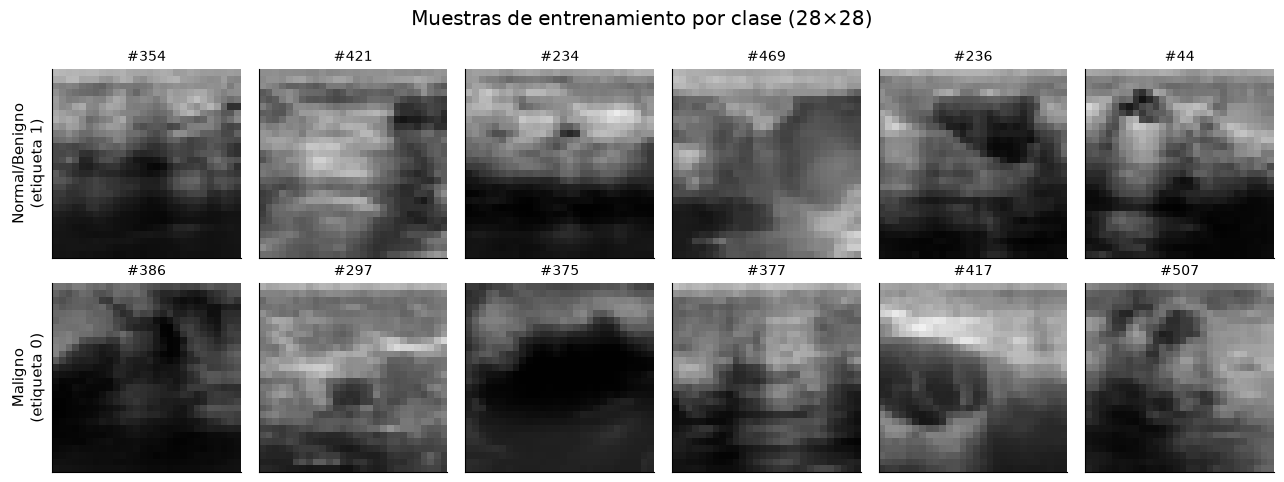

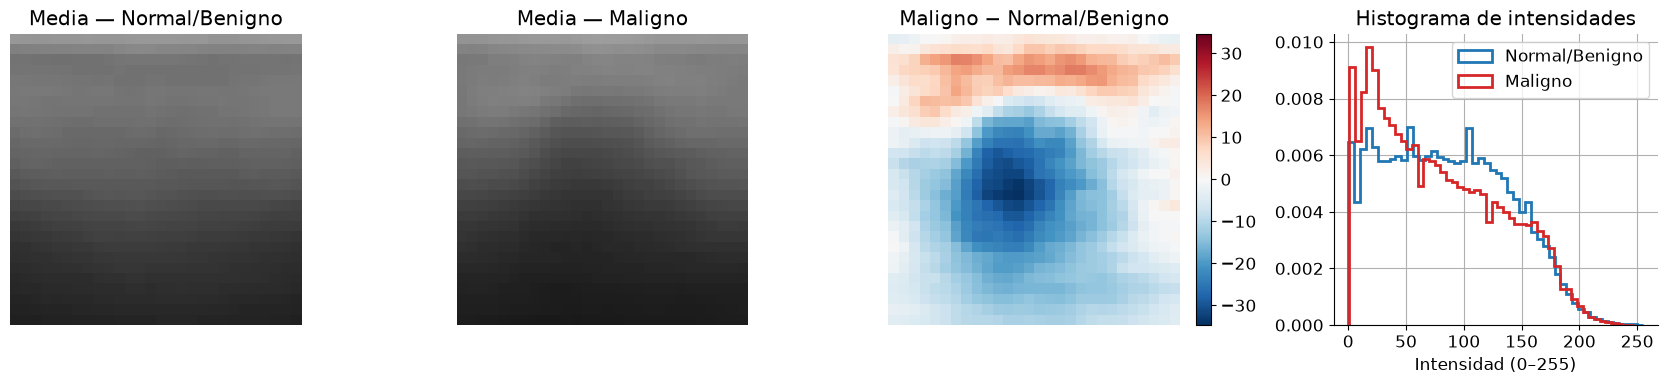

Intensidad media — Normal/Benigno: 85.5  |  Maligno: 78.2


In [4]:
# TODO: Escribe tu código de visualización aquí

# --- Resolución ---
n_muestras = 6                                # al menos 3 por clase (se muestran 6)
rng = np.random.default_rng(RANDOM_STATE)

fig, axs = plt.subplots(2, n_muestras, figsize=(13, 5))
for fila, clase in enumerate([IDX_NOMAL, IDX_MAL]):
    idx = rng.choice(np.flatnonzero(y_train == clase), n_muestras, replace=False)
    for j, k in enumerate(idx):
        axs[fila, j].imshow(X_train[k], cmap='gray', vmin=0, vmax=255)
        axs[fila, j].set_title(f'#{k}', fontsize=10)
        axs[fila, j].set_xticks([]); axs[fila, j].set_yticks([])
    axs[fila, 0].set_ylabel(f'{NOMBRES[clase]}\n(etiqueta {clase})', fontsize=11)
plt.suptitle('Muestras de entrenamiento por clase (28×28)')
plt.tight_layout(); plt.show()

# Imagen media por clase, su diferencia e histograma de intensidades
media_nomal = X_train[y_train == IDX_NOMAL].mean(axis=0)
media_mal   = X_train[y_train == IDX_MAL].mean(axis=0)
dif = media_mal - media_nomal
lim = np.abs(dif).max()

fig, axs = plt.subplots(1, 4, figsize=(17, 4))
axs[0].imshow(media_nomal, cmap='gray', vmin=0, vmax=255); axs[0].set_title('Media — Normal/Benigno')
axs[1].imshow(media_mal, cmap='gray', vmin=0, vmax=255);   axs[1].set_title('Media — Maligno')
im = axs[2].imshow(dif, cmap='RdBu_r', vmin=-lim, vmax=lim); axs[2].set_title('Maligno − Normal/Benigno')
plt.colorbar(im, ax=axs[2], fraction=0.046)
for ax in axs[:3]:
    ax.axis('off')
for clase, color in [(IDX_NOMAL, 'C0'), (IDX_MAL, 'C3')]:
    axs[3].hist(X_train[y_train == clase].ravel(), bins=50, density=True, histtype='step', lw=2,
                color=color, label=NOMBRES[clase])
axs[3].set_title('Histograma de intensidades'); axs[3].set_xlabel('Intensidad (0–255)'); axs[3].legend()
plt.tight_layout(); plt.show()

print(f'Intensidad media — Normal/Benigno: {X_train[y_train == IDX_NOMAL].mean():.1f}  |  '
      f'Maligno: {X_train[y_train == IDX_MAL].mean():.1f}')

**Respuesta — ¿hay alguna diferencia visual obvia?**

No a simple vista. A 28×28 píxeles el *speckle* (granulado típico de la ecografía) domina la imagen y los bordes de la lesión quedan muy suavizados. Además, la clase 1 mezcla imágenes **normales** (sin lesión) con **benignas**, así que es muy heterogénea. Las diferencias son de tendencia y no permiten clasificar una imagen sola a ojo:
- Las lesiones malignas suelen verse como zonas oscuras (hipoecoicas) de **contorno irregular**, a veces con una **sombra acústica** debajo.
- Las benignas tienden a ser **ovaladas y de borde nítido**, y las normales muestran solo capas de tejido.
- La imagen media de cada clase y su diferencia (mapa rojo/azul) indican en qué regiones cambia en promedio el brillo entre clases. Esa variación sistemática es la que PCA y el clasificador pueden aprovechar aunque no se note en una imagen individual.

## 2. Preprocesamiento y Vectorización
Para aplicar PCA o SVD estándar, necesitamos que cada imagen (una matriz 2D de 28x28) se convierta en un vector 1D (784 píxeles).

### Consigna 2: Vectorización y Centrado
1. Transforma `X_train` y `X_test` de dimensiones `(N, 28, 28)` a `(N, 784)`.
2. Calcula el **rostro (imagen) medio** del conjunto de entrenamiento y réstalo a todas las imágenes (tanto de train como de test) para centrar los datos.

X_train: (546, 28, 28) -> X_train_vec: (546, 784)  |  X_test: (156, 28, 28) -> X_test_vec: (156, 784)
Rango tras normalizar: [0.00, 1.00]
Media por píxel tras centrar — train: máx |μ| = 1.2e-15  |  test: máx |μ| = 0.041 (no es 0: se usa la media de train)


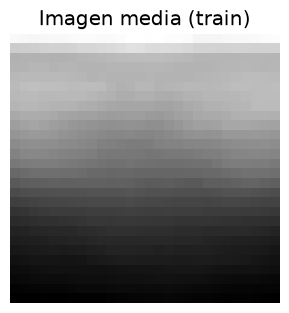

In [5]:
# TODO: Escribe tu código de preprocesamiento y centrado aquí

# --- Resolución ---
# 1. Vectorización (flattening): (N, 28, 28) -> (N, 784), con normalización a [0, 1]
#    (se conservan X_train y X_test originales, uint8, para visualizar)
X_train_vec = X_train.reshape(X_train.shape[0], -1).astype(np.float64) / 255.0
X_test_vec  = X_test.reshape(X_test.shape[0], -1).astype(np.float64) / 255.0

# 2. Imagen media de ENTRENAMIENTO y centrado de ambos conjuntos con esa misma media
#    (el test no aporta a la media: así no hay fuga de información)
imagen_media = X_train_vec.mean(axis=0)
X_train_centrado = X_train_vec - imagen_media
X_test_centrado  = X_test_vec - imagen_media

n, d = X_train_centrado.shape
print(f'X_train: {X_train.shape} -> X_train_vec: {X_train_vec.shape}  |  X_test: {X_test.shape} -> X_test_vec: {X_test_vec.shape}')
print(f'Rango tras normalizar: [{X_train_vec.min():.2f}, {X_train_vec.max():.2f}]')
print(f'Media por píxel tras centrar — train: máx |μ| = {np.abs(X_train_centrado.mean(axis=0)).max():.1e}  |  '
      f'test: máx |μ| = {np.abs(X_test_centrado.mean(axis=0)).max():.3f} (no es 0: se usa la media de train)')

plt.figure(figsize=(3.5, 3.5))
plt.imshow(imagen_media.reshape(28, 28), cmap='gray')
plt.title('Imagen media (train)'); plt.axis('off'); plt.show()

*Nota:* además de aplanar y centrar se dividió por 255 para llevar los píxeles a $[0, 1]$ (normalización). No cambia las direcciones principales, solo la escala de los valores singulares, y deja los números en un rango cómodo. El conjunto de prueba se centra con la media de **entrenamiento**, igual que en el ejemplo de *eigenfaces* de la práctica C8: en un uso real, la media de las imágenes nuevas no se conoce de antemano.

## 3. Reducción de Dimensionalidad con SVD / PCA
Ahora aplicaremos SVD a nuestra matriz de datos centrados para extraer los **Componentes Principales** (las "Eigen-imágenes").

### Consigna 3: Cálculo de SVD
1. Aplica SVD a la matriz de entrenamiento centrada para obtener `U`, `S` y `V^T`.
2. Grafica la varianza explicada acumulada y decide un valor de `r` (número de componentes) que conserve al menos el 90% de la energía/varianza.
3. Visualiza los primeros 5 componentes principales (Eigen-imágenes) redimensionándolos de nuevo a 28x28.

U: (546, 546)  |  S: (546,)  |  Vt: (546, 784)  |  tiempo: 170 ms
Error de reconstrucción exacta ||Xc − UΣVᵀ||/||Xc|| = 1.9e-15


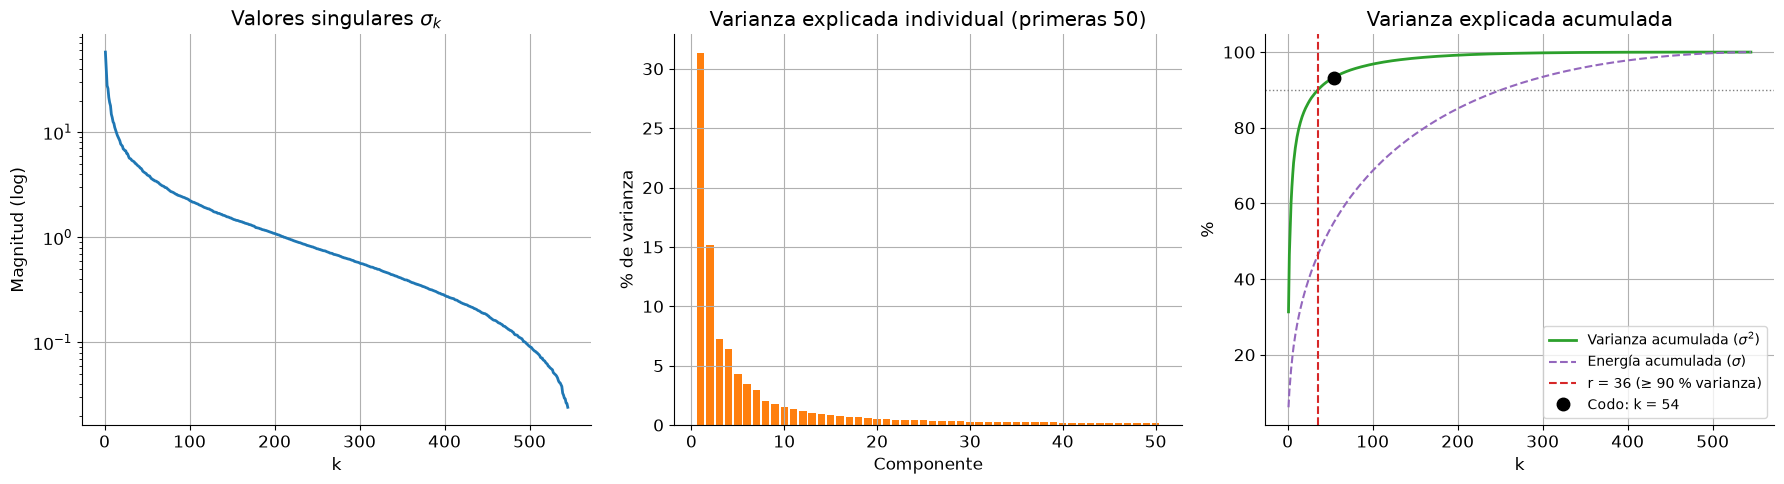

r elegido = 36 componentes → 90.1% de la varianza (4.6% de las 784 dimensiones)
Referencias: 90 % de la energía (Σσ) → k = 252  |  codo de la curva → k = 54 (93.3%)


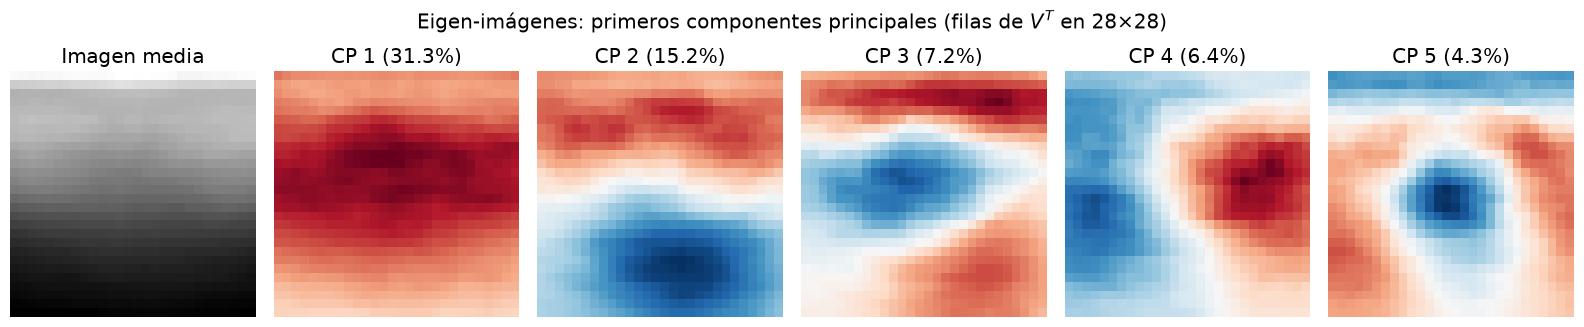

In [6]:
# TODO: Escribe tu código de SVD y visualización aquí

# --- Resolución ---
# 1. SVD económica de la matriz centrada: X_c = U Σ Vᵀ (cada fila de X_c es una imagen)
t0 = time.perf_counter()
U, S, Vt = np.linalg.svd(X_train_centrado, full_matrices=False)
t_svd = time.perf_counter() - t0
print(f'U: {U.shape}  |  S: {S.shape}  |  Vt: {Vt.shape}  |  tiempo: {t_svd * 1e3:.0f} ms')
print(f'Error de reconstrucción exacta ||Xc − UΣVᵀ||/||Xc|| = '
      f'{np.linalg.norm(X_train_centrado - (U * S) @ Vt) / np.linalg.norm(X_train_centrado):.1e}')

# 2. Varianza explicada (∝ σ²) y energía (∝ σ), individuales y acumuladas
var_exp  = S**2 / np.sum(S**2)
var_acum = np.cumsum(var_exp)
energia_acum = np.cumsum(S) / np.sum(S)
kk = np.arange(1, len(S) + 1)
r_util = min(n - 1, d)          # componentes con varianza no nula (el centrado quita un grado de libertad)

r = int(np.searchsorted(var_acum, 0.90) + 1)            # mínimo r con ≥ 90 % de varianza
r_energia = int(np.searchsorted(energia_acum, 0.90) + 1)  # mismo criterio con la energía (Σσ)

# Codo de la varianza acumulada: punto más alejado de la recta entre extremos (ejes normalizados)
x_n = (kk[:r_util] - 1) / (r_util - 1)
y_n = (var_acum[:r_util] - var_acum[0]) / (var_acum[r_util - 1] - var_acum[0])
r_codo = int(kk[np.argmax(y_n - x_n)])

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].semilogy(kk[:r_util], S[:r_util], lw=2, color='C0')   # se omite σ ≈ 0 del centrado
axs[0].set_title('Valores singulares $\\sigma_k$'); axs[0].set_xlabel('k'); axs[0].set_ylabel('Magnitud (log)')

n_vis = 50
axs[1].bar(kk[:n_vis], var_exp[:n_vis] * 100, color='C1')
axs[1].set_title(f'Varianza explicada individual (primeras {n_vis})')
axs[1].set_xlabel('Componente'); axs[1].set_ylabel('% de varianza')

axs[2].plot(kk[:r_util], var_acum[:r_util] * 100, lw=2, color='C2', label='Varianza acumulada ($\\sigma^2$)')
axs[2].plot(kk[:r_util], energia_acum[:r_util] * 100, lw=1.5, ls='--', color='C4', label='Energía acumulada ($\\sigma$)')
axs[2].axhline(90, color='gray', ls=':', lw=1)
axs[2].axvline(r, color='C3', ls='--', lw=1.5, label=f'r = {r} (≥ 90 % varianza)')
axs[2].plot(r_codo, var_acum[r_codo - 1] * 100, 'o', ms=9, color='k', label=f'Codo: k = {r_codo}')
axs[2].set_title('Varianza explicada acumulada'); axs[2].set_xlabel('k'); axs[2].set_ylabel('%')
axs[2].legend(loc='lower right', fontsize=10)
plt.tight_layout(); plt.show()

print(f'r elegido = {r} componentes → {var_acum[r - 1]:.1%} de la varianza ({r / d:.1%} de las {d} dimensiones)')
print(f'Referencias: 90 % de la energía (Σσ) → k = {r_energia}  |  codo de la curva → k = {r_codo} ({var_acum[r_codo - 1]:.1%})')

# 3. Primeros 5 componentes principales (eigen-imágenes) = primeras filas de Vᵀ
n_comp = 5
fig, axs = plt.subplots(1, n_comp + 1, figsize=(16, 3.4))
axs[0].imshow(imagen_media.reshape(28, 28), cmap='gray'); axs[0].set_title('Imagen media')
for i in range(n_comp):
    v = Vt[i].reshape(28, 28)
    lim = np.abs(v).max()
    axs[i + 1].imshow(v, cmap='RdBu_r', vmin=-lim, vmax=lim)       # el signo de cada CP es arbitrario
    axs[i + 1].set_title(f'CP {i + 1} ({var_exp[i]:.1%})')
for ax in axs:
    ax.axis('off')
plt.suptitle('Eigen-imágenes: primeros componentes principales (filas de $V^T$ en 28×28)')
plt.tight_layout(); plt.show()

**Interpretación.**
- Como cada **fila** de `X_train_centrado` es una imagen, las eigen-imágenes son las **filas de $V^T$**. En la práctica C8, con las caras, cada imagen era una columna y las eigenfaces salían de $U$.
- El valor de `r` se eligió como el mínimo número de componentes que conserva el 90 % de la **varianza** ($\sum \sigma_i^2$), que es lo que mide PCA. Se muestra también la **energía** ($\sum \sigma_i$, curva punteada): alcanzar el 90 % de energía pide más componentes porque $\sigma$ decae más lento que $\sigma^2$.
- El **codo** marca dónde la curva acumulada deja de crecer rápido; a partir de ahí cada componente extra aporta poca varianza.
- Las primeras eigen-imágenes son patrones suaves y globales (brillo general, gradientes arriba/abajo o izquierda/derecha); las siguientes agregan detalle cada vez más fino.

### Complemento 3.a: matriz de covarianza y su relación con la SVD *(celda agregada)*
La matriz de covarianza de los píxeles es

$$C = \frac{1}{n-1} X_c^T X_c = V\,\frac{\Sigma^2}{n-1}\,V^T .$$

Sus autovectores son las columnas de $V$ (las eigen-imágenes) y sus autovalores son $\lambda_i = \sigma_i^2/(n-1)$, la varianza a lo largo de cada dirección. Con $d = 784$, $C$ ($784 \times 784$) se puede calcular directamente y comparar con la SVD.

C: (784, 784)  |  simétrica: True
λ (autovalores de C) : [6.1333 2.9661 1.4121 1.2475 0.843 ]
σ²/(n−1) (de la SVD)  : [6.1333 2.9661 1.4121 1.2475 0.843 ]
Máx. error relativo en los 545 autovalores no nulos: 1.3e-11
Autovectores de C = filas de Vᵀ (±signo, primeras 10): True
Varianza total: traza(C) = 19.5746 = Σλ = 19.5746


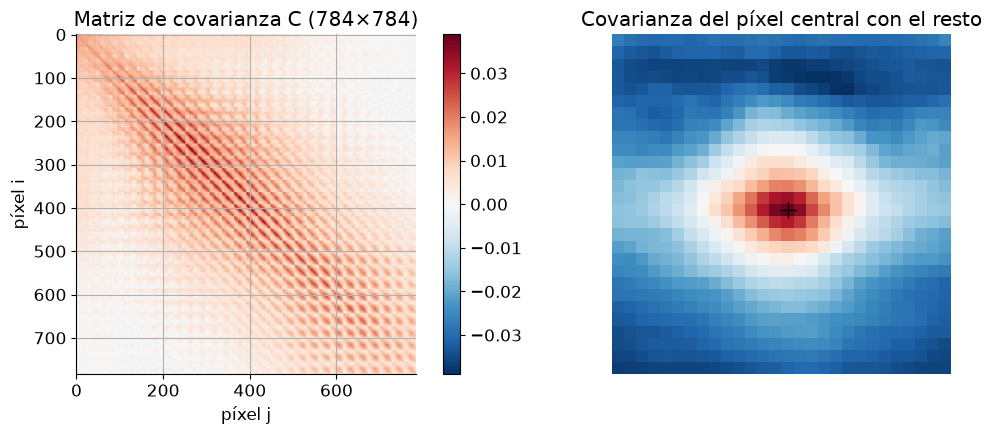

In [7]:
C = np.cov(X_train_centrado, rowvar=False)            # (784, 784) = Xcᵀ Xc / (n−1)
lam, V_eig = np.linalg.eigh(C)                         # eigh: C es simétrica
orden = np.argsort(lam)[::-1]
lam, V_eig = lam[orden], V_eig[:, orden]

lam_svd = S**2 / (n - 1)
m = min(n - 1, d)                                       # autovalores no nulos (el centrado quita 1 grado de libertad)
print(f'C: {C.shape}  |  simétrica: {np.allclose(C, C.T)}')
print('λ (autovalores de C) :', np.round(lam[:5], 4))
print('σ²/(n−1) (de la SVD)  :', np.round(lam_svd[:5], 4))
print(f'Máx. error relativo en los {m} autovalores no nulos: {np.max(np.abs(lam[:m] - lam_svd[:m]) / lam_svd[:m]):.1e}')
print(f'Autovectores de C = filas de Vᵀ (±signo, primeras 10): '
      f'{np.allclose(np.abs(V_eig[:, :10].T), np.abs(Vt[:10]), atol=1e-8)}')
print(f'Varianza total: traza(C) = {np.trace(C):.4f} = Σλ = {lam_svd.sum():.4f}')

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
im = axs[0].imshow(C, cmap='RdBu_r', vmin=-np.abs(C).max(), vmax=np.abs(C).max())
axs[0].set_title('Matriz de covarianza C (784×784)'); axs[0].set_xlabel('píxel j'); axs[0].set_ylabel('píxel i')
plt.colorbar(im, ax=axs[0], fraction=0.046)
p_centro = 14 * 28 + 14
axs[1].imshow(C[p_centro].reshape(28, 28), cmap='RdBu_r')
axs[1].plot(14, 14, 'k+', ms=12); axs[1].axis('off')
axs[1].set_title('Covarianza del píxel central con el resto')
plt.tight_layout(); plt.show()

Los autovalores de $C$ coinciden con $\sigma_i^2/(n-1)$ y sus autovectores con las filas de $V^T$: **PCA es la SVD de la matriz centrada**. La SVD es preferible en la práctica porque no forma $X_c^T X_c$, que eleva al cuadrado el número de condición, y porque escala mejor cuando $d$ es grande. La covarianza del píxel central muestra que cada píxel está muy correlacionado con sus vecinos: esa redundancia es la que permite comprimir.

### Complemento 3.b: reconstrucción con distintos $k$ *(celda agregada)*
La reconstrucción de rango $k$ de una imagen es $\hat{x}_k = \mu + V_k V_k^T (x - \mu)$, con $V_k$ las primeras $k$ filas de $V^T$ traspuestas. Se reconstruyen imágenes de **prueba** (no usadas para calcular la base) y se reporta el error relativo $\|x - \hat{x}_k\| / \|x\|$.

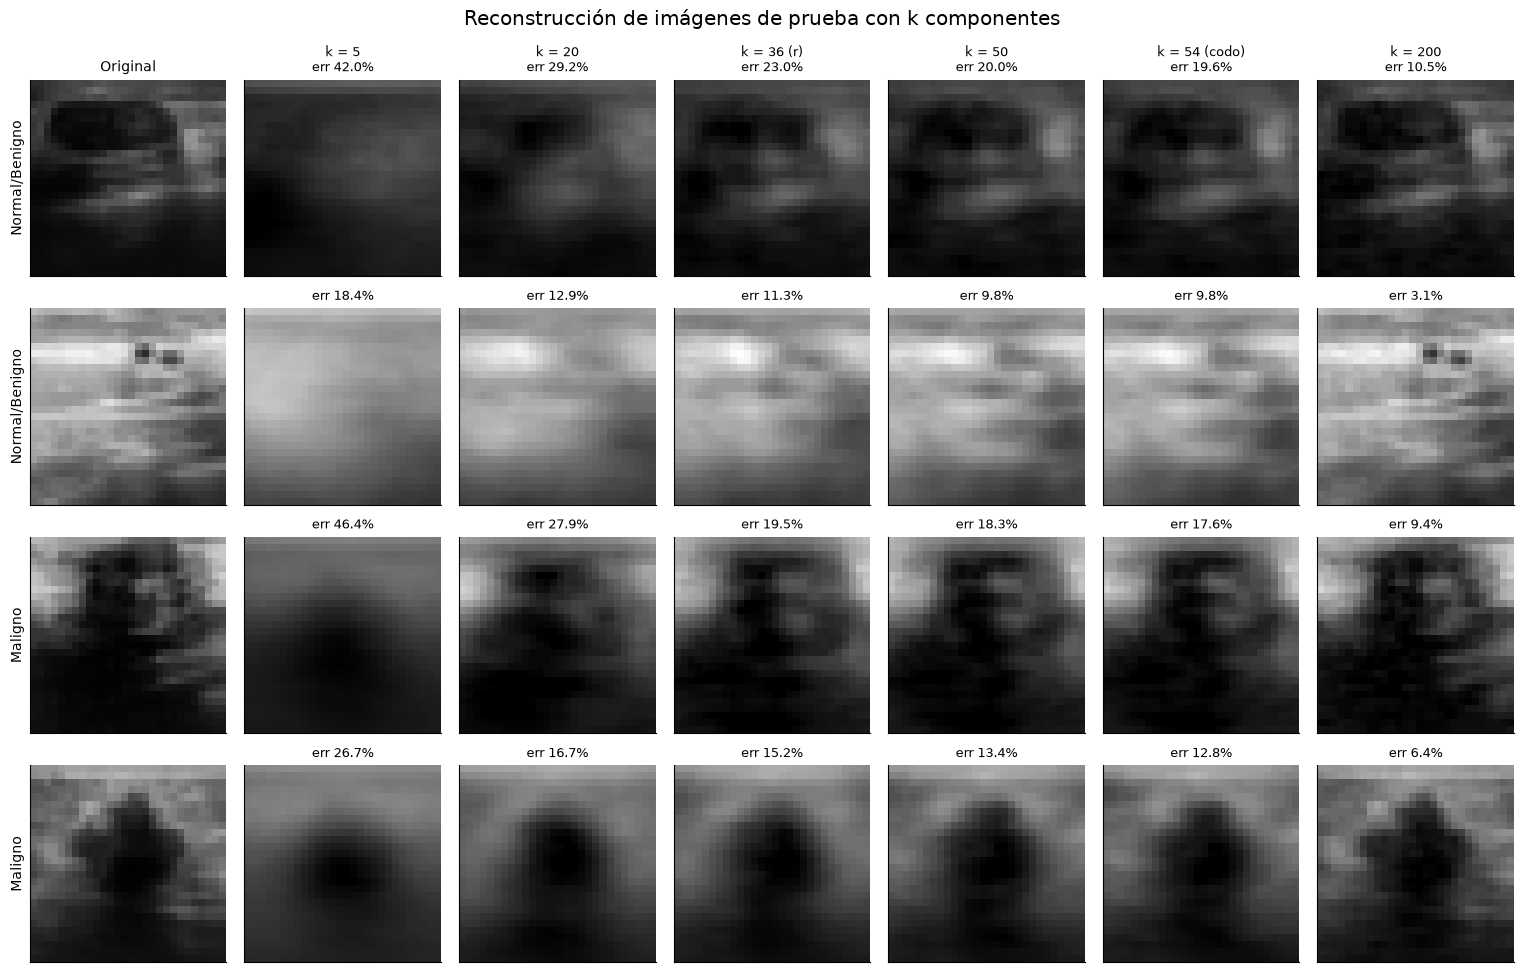

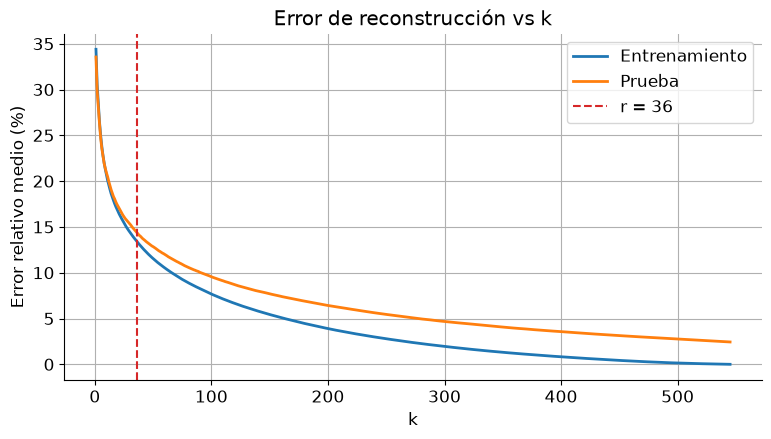

   k   error train   error test   almacenamiento por imagen
   5        25.0%        24.7%      5 coef. de 784 (0.6%)
  20        16.7%        17.2%     20 coef. de 784 (2.6%)
  36        13.4%        14.4%     36 coef. de 784 (4.6%)
  50        11.5%        12.8%     50 coef. de 784 (6.4%)
  54        11.1%        12.5%     54 coef. de 784 (6.9%)
 200         3.9%         6.4%    200 coef. de 784 (25.5%)


In [8]:
def reconstruir(Xc_filas, k):
    # Proyecta en las k primeras direcciones principales y vuelve al espacio de píxeles
    return imagen_media + (Xc_filas @ Vt[:k].T) @ Vt[:k]

k_lista = sorted({5, 20, 50, r, r_codo, 200})
idx_vis = [np.flatnonzero(y_test == IDX_NOMAL)[0], np.flatnonzero(y_test == IDX_NOMAL)[1],
           np.flatnonzero(y_test == IDX_MAL)[0], np.flatnonzero(y_test == IDX_MAL)[1]]

fig, axs = plt.subplots(len(idx_vis), len(k_lista) + 1, figsize=(2.2 * (len(k_lista) + 1), 2.5 * len(idx_vis)))
for i, j in enumerate(idx_vis):
    x = X_test_vec[j]
    axs[i, 0].imshow(x.reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    axs[i, 0].set_ylabel(NOMBRES[y_test[j]], fontsize=10)
    if i == 0:
        axs[i, 0].set_title('Original', fontsize=10)
    for col, k in enumerate(k_lista, start=1):
        x_hat = reconstruir(X_test_centrado[j:j + 1], k)[0]
        err = np.linalg.norm(x - x_hat) / np.linalg.norm(x)
        axs[i, col].imshow(np.clip(x_hat, 0, 1).reshape(28, 28), cmap='gray', vmin=0, vmax=1)
        marca = ' (r)' if k == r else (' (codo)' if k == r_codo else '')
        axs[i, col].set_title((f'k = {k}{marca}\n' if i == 0 else '') + f'err {err:.1%}', fontsize=9)
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Reconstrucción de imágenes de prueba con k componentes')
plt.tight_layout(); plt.show()

# Error relativo medio vs k. Como las filas de Vᵀ son ortonormales:
# ||xc − V_k V_kᵀ xc||² = ||xc||² − Σ_{j≤k} z_j², así la curva completa sale de una sola proyección
def error_vs_k(X_vec, Xc):
    Z = Xc @ Vt.T
    resid2 = np.sum(Xc**2, axis=1, keepdims=True) - np.cumsum(Z**2, axis=1)
    return (np.sqrt(np.clip(resid2, 0, None)) / np.linalg.norm(X_vec, axis=1, keepdims=True)).mean(axis=0)

err_tr, err_te = error_vs_k(X_train_vec, X_train_centrado), error_vs_k(X_test_vec, X_test_centrado)
plt.figure(figsize=(9, 4.5))
plt.plot(kk[:r_util], err_tr[:r_util] * 100, lw=2, label='Entrenamiento')
plt.plot(kk[:r_util], err_te[:r_util] * 100, lw=2, label='Prueba')
plt.axvline(r, color='C3', ls='--', label=f'r = {r}')
plt.xlabel('k'); plt.ylabel('Error relativo medio (%)'); plt.title('Error de reconstrucción vs k')
plt.legend(); plt.show()

print('   k   error train   error test   almacenamiento por imagen')
for k in k_lista:
    print(f'{k:>4}   {err_tr[k - 1]:>10.1%}   {err_te[k - 1]:>10.1%}   {k:>4} coef. de {d} ({k / d:.1%})')

Con pocas componentes la reconstrucción conserva la forma general (zonas claras y oscuras) y pierde el *speckle* y los bordes finos. Al aumentar $k$ el error baja, pero cada vez más despacio. En entrenamiento el error llega a 0 al usar todas las componentes (teorema de Eckart–Young). En prueba se estanca: las imágenes nuevas tienen variaciones que la base aprendida con 546 imágenes no puede generar.

### Complemento 3.c: proyección sobre las dos primeras componentes *(celda agregada)*

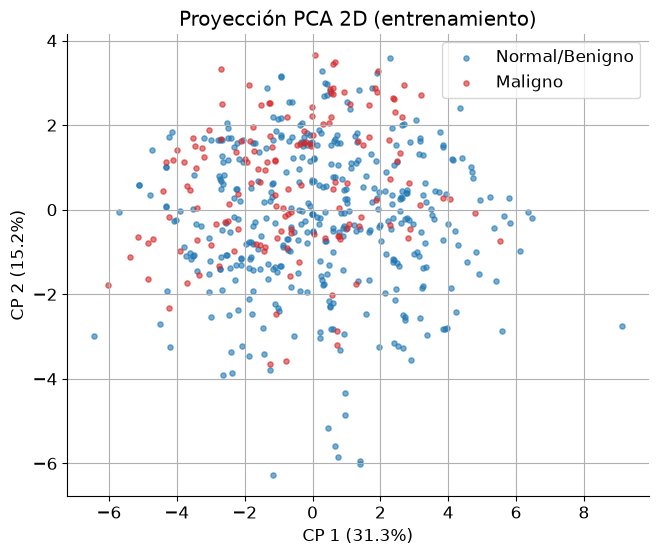

In [9]:
Z2 = X_train_centrado @ Vt[:2].T
plt.figure(figsize=(7.5, 6))
for clase, color in [(IDX_NOMAL, 'C0'), (IDX_MAL, 'C3')]:
    m_c = y_train == clase
    plt.scatter(Z2[m_c, 0], Z2[m_c, 1], s=14, alpha=0.6, color=color, label=NOMBRES[clase])
plt.xlabel(f'CP 1 ({var_exp[0]:.1%})'); plt.ylabel(f'CP 2 ({var_exp[1]:.1%})')
plt.title('Proyección PCA 2D (entrenamiento)'); plt.legend(); plt.show()

Las dos clases se superponen mucho en el plano de las dos primeras componentes. PCA elige las direcciones de **máxima varianza sin mirar las etiquetas**, y la varianza más grande (brillo, posición del tejido) no tiene por qué ser la que separa maligno de benigno. Por eso el clasificador necesita más de dos componentes.

## 4. Proyección y Clasificación
Una vez que tenemos la matriz de proyección (los primeros `r` componentes de `V^T` o equivalentemente usando Scikit-Learn `PCA`), proyectaremos los datos a un espacio de menor dimensión.

### Consigna 4: Clasificador Predictivo
1. Proyecta `X_train_centrado` y `X_test_centrado` sobre los primeros `r` componentes principales.
2. Entrena un clasificador simple, como **Regresión Logística** o **k-Nearest Neighbors (k-NN)**, usando las proyecciones de entrenamiento.
3. Evalúa el modelo en el conjunto de prueba usando `accuracy_score` y `classification_report`.
4. Prueba variar el número de componentes `r` (ej: 5, 20, 50) y describe cómo afecta el rendimiento.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# TODO: Escribe tu código de clasificación aquí

# --- Resolución ---
# 1. Proyección sobre los primeros r componentes: Z = X_c V_r  (coordenadas en la base PCA)
Vr = Vt[:r].T                                     # (784, r)
Z_train = X_train_centrado @ Vr
Z_test  = X_test_centrado @ Vr
print(f'r = {r}  |  Z_train: {Z_train.shape}  |  Z_test: {Z_test.shape}\n')

# 2. Clasificadores entrenados con las proyecciones de entrenamiento
#    - Regresión Logística: se estandarizan las r coordenadas (escalas muy distintas entre CP)
#      y se compensa el desbalance con class_weight='balanced'
#    - k-NN (k = 5): sin estandarizar, para que la distancia en Z sea la distancia euclídea
#      entre imágenes reconstruidas
def crear_modelos():
    return {
        'Regresión Logística': make_pipeline(
            StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=5000)),
        'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5),
    }

target_names = [NOMBRES[c] for c in sorted(NOMBRES)]    # en orden de etiqueta (0, 1)
modelos_r = {}
for nombre, modelo in crear_modelos().items():
    modelo.fit(Z_train, y_train)
    y_pred = modelo.predict(Z_test)
    modelos_r[nombre] = modelo
    # 3. Evaluación en prueba
    print(f'=== {nombre} — r = {r} ===')
    print(f'accuracy = {accuracy_score(y_test, y_pred):.3f}')
    print(classification_report(y_test, y_pred, target_names=target_names, digits=3))

print(f'Referencia: responder siempre "{NOMBRES[IDX_NOMAL]}" da accuracy = {np.mean(y_test == IDX_NOMAL):.3f}')

r = 36  |  Z_train: (546, 36)  |  Z_test: (156, 36)

=== Regresión Logística — r = 36 ===
accuracy = 0.737
                precision    recall  f1-score   support

       Maligno      0.511     0.548     0.529        42
Normal/Benigno      0.829     0.807     0.818       114

      accuracy                          0.737       156
     macro avg      0.670     0.677     0.673       156
  weighted avg      0.743     0.737     0.740       156

=== k-NN (k=5) — r = 36 ===
accuracy = 0.776
                precision    recall  f1-score   support

       Maligno      0.684     0.310     0.426        42
Normal/Benigno      0.788     0.947     0.861       114

      accuracy                          0.776       156
     macro avg      0.736     0.628     0.643       156
  weighted avg      0.760     0.776     0.744       156

Referencia: responder siempre "Normal/Benigno" da accuracy = 0.731


#### Consigna 4.4: efecto del número de componentes $r$ *(celda agregada)*
Se repite el entrenamiento para varios $r$, incluidos los pedidos (5, 20, 50), el $r$ del 90 % y el codo. Además del *accuracy* se reporta el F1 de la clase maligna, que es más informativo con clases desbalanceadas.

       var. retenida            Accuracy                     F1 maligno           
Modelo               Regresión Logística k-NN (k=5) Regresión Logística k-NN (k=5)
r                                                                                 
2              0.465               0.641      0.712               0.481      0.308
5              0.644               0.718      0.750               0.569      0.381
10             0.761               0.756      0.756               0.596      0.441
20             0.846               0.769      0.782               0.617      0.433
36             0.901               0.737      0.776               0.529      0.426
50             0.927               0.750      0.782               0.562      0.485
54             0.933               0.744      0.782               0.545      0.500
100            0.968               0.744      0.776               0.574      0.493
200            0.992               0.731      0.769               0.553      0.486


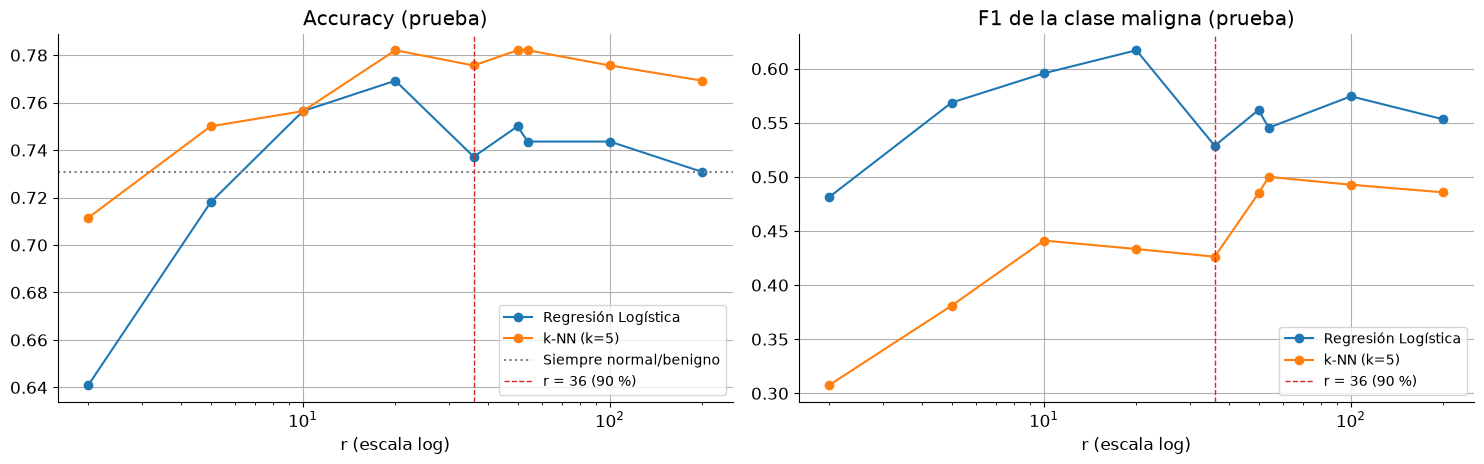

Regresión Logística: mejor F1 maligno = 0.617 con r = 20  |  mejor accuracy = 0.769 con r = 20
k-NN (k=5): mejor F1 maligno = 0.500 con r = 54  |  mejor accuracy = 0.782 con r = 20


In [11]:
r_valores = sorted({2, 5, 10, 20, 50, 100, 200, r, r_codo})
filas = []
for rr in r_valores:
    Ztr, Zte = X_train_centrado @ Vt[:rr].T, X_test_centrado @ Vt[:rr].T
    for nombre, modelo in crear_modelos().items():
        y_pred = modelo.fit(Ztr, y_train).predict(Zte)
        filas.append({'r': rr, 'Modelo': nombre, 'var. retenida': var_acum[rr - 1],
                      'Accuracy': accuracy_score(y_test, y_pred),
                      'F1 maligno': f1_score(y_test, y_pred, pos_label=IDX_MAL),
                      'Sensib. maligno': recall_score(y_test, y_pred, pos_label=IDX_MAL)})
df_r = pd.DataFrame(filas)

tabla_r = df_r.pivot(index='r', columns='Modelo', values=['Accuracy', 'F1 maligno'])
tabla_r.insert(0, ('var. retenida', ''), df_r.groupby('r')['var. retenida'].first())
print(tabla_r.to_string(float_format=lambda v: f'{v:.3f}'))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
for nombre, color in [('Regresión Logística', 'C0'), ('k-NN (k=5)', 'C1')]:
    sub = df_r[df_r['Modelo'] == nombre]
    axs[0].plot(sub['r'], sub['Accuracy'], 'o-', color=color, label=nombre)
    axs[1].plot(sub['r'], sub['F1 maligno'], 'o-', color=color, label=nombre)
axs[0].axhline(np.mean(y_test == IDX_NOMAL), color='gray', ls=':', label='Siempre normal/benigno')
for ax, titulo in zip(axs, ['Accuracy (prueba)', 'F1 de la clase maligna (prueba)']):
    ax.axvline(r, color='C3', ls='--', lw=1, label=f'r = {r} (90 %)')
    ax.set_xscale('log'); ax.set_xlabel('r (escala log)'); ax.set_title(titulo); ax.legend(fontsize=10)
plt.tight_layout(); plt.show()

for nombre in ['Regresión Logística', 'k-NN (k=5)']:
    sub = df_r[df_r['Modelo'] == nombre].set_index('r')
    print(f"{nombre}: mejor F1 maligno = {sub['F1 maligno'].max():.3f} con r = {sub['F1 maligno'].idxmax()}  |  "
          f"mejor accuracy = {sub['Accuracy'].max():.3f} con r = {sub['Accuracy'].idxmax()}")

**Cómo afecta $r$ al rendimiento.**
- **$r$ muy chico (2–5):** se pierde información discriminante. Las primeras componentes describen sobre todo brillo y forma global, que no separan las clases, y el rendimiento queda cerca de la referencia de ≈73 %.
- **$r$ intermedio (decenas):** el rendimiento sube rápido. Las componentes que se agregan contienen detalles (forma y contraste de la lesión) relevantes para distinguir maligno de benigno.
- **$r$ grande:** el beneficio se satura o incluso empeora. Las últimas componentes son mayormente ruido (*speckle*) y, con solo 546 imágenes de entrenamiento, aumentan el riesgo de sobreajuste en la Regresión Logística. En el k-NN la distancia empieza a dominarse por dimensiones irrelevantes (maldición de la dimensionalidad).
- El $r$ del 90 % de varianza es un criterio **de compresión**, no de clasificación: el mejor $r$ para clasificar puede estar por debajo. La tabla de arriba muestra dónde cae en este caso.

*Nota metodológica:* la consigna pide comparar los $r$ sobre el conjunto de prueba. Para **elegir** $r$ de forma estricta habría que usar validación cruzada en entrenamiento o la partición `val`, y dejar `test` solo para el informe final.

### Complemento 4.a: métricas completas — F1, matriz de confusión y Curva ROC *(celda agregada)*
Clase positiva = **maligno**. Para la Curva ROC se usa la probabilidad estimada de la clase maligna.

Regresión Logística  accuracy = 0.737 | precisión = 0.511 | sensibilidad = 0.548 | F1 = 0.529
k-NN (k=5)           accuracy = 0.776 | precisión = 0.684 | sensibilidad = 0.310 | F1 = 0.426


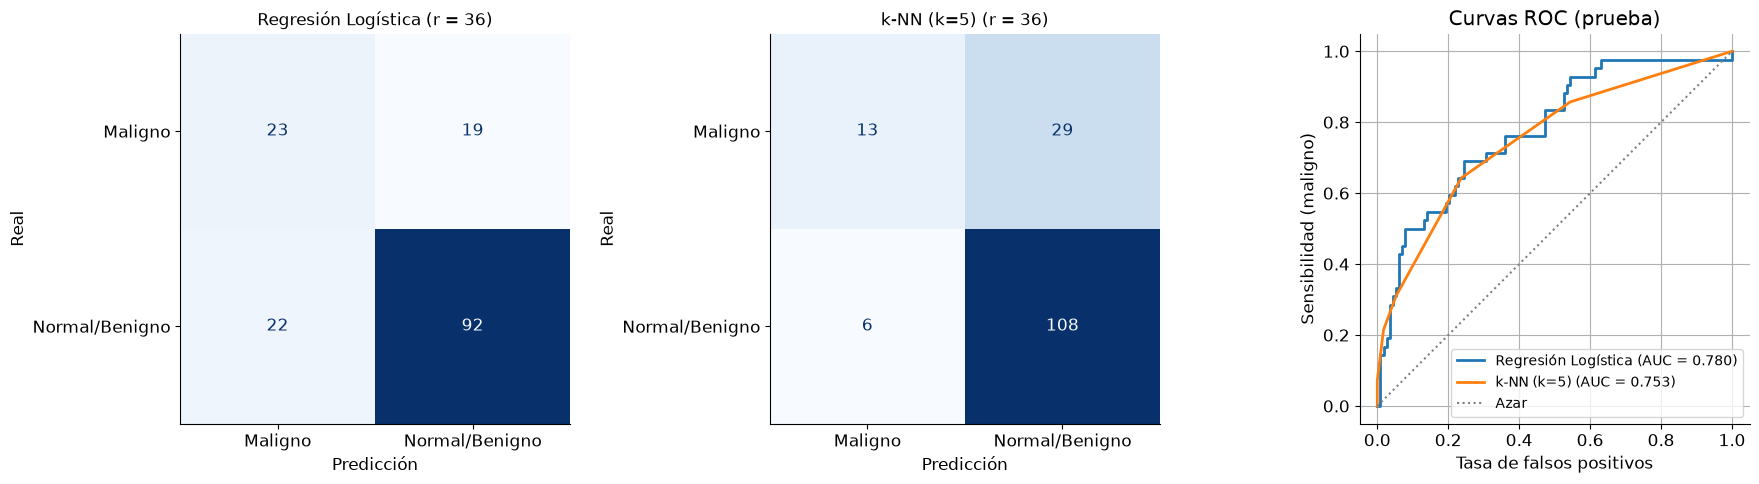

In [12]:
def puntaje_maligno(modelo, Z):
    # Probabilidad de la clase maligna (columna correspondiente en predict_proba)
    return modelo.predict_proba(Z)[:, list(modelo.classes_).index(IDX_MAL)]

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, modelo) in zip(axs[:2], modelos_r.items()):
    y_pred = modelo.predict(Z_test)
    cm = confusion_matrix(y_test, y_pred, labels=[IDX_MAL, IDX_NOMAL])
    ConfusionMatrixDisplay(cm, display_labels=['Maligno', 'Normal/Benigno']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{nombre} (r = {r})', fontsize=12); ax.grid(False)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')

    s_mal = puntaje_maligno(modelo, Z_test)
    fpr, tpr, _ = roc_curve(y_test == IDX_MAL, s_mal)
    axs[2].plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_score(y_test == IDX_MAL, s_mal):.3f})')
    print(f'{nombre:<20} accuracy = {accuracy_score(y_test, y_pred):.3f} | '
          f'precisión = {precision_score(y_test, y_pred, pos_label=IDX_MAL):.3f} | '
          f'sensibilidad = {recall_score(y_test, y_pred, pos_label=IDX_MAL):.3f} | '
          f'F1 = {f1_score(y_test, y_pred, pos_label=IDX_MAL):.3f}')
axs[2].plot([0, 1], [0, 1], ':', color='gray', label='Azar')
axs[2].set_xlabel('Tasa de falsos positivos'); axs[2].set_ylabel('Sensibilidad (maligno)')
axs[2].set_title('Curvas ROC (prueba)'); axs[2].legend(loc='lower right', fontsize=10)
axs[2].set_aspect('equal')
plt.tight_layout(); plt.show()

En la matriz de confusión, la fila **Maligno** muestra cuántos tumores malignos se detectaron y cuántos se clasificaron como normales/benignos (**falsos negativos**). En este problema el falso negativo es el error más grave: un cáncer que no se deriva a biopsia. La Curva ROC muestra el compromiso entre sensibilidad y falsos positivos al mover el umbral de decisión. El AUC resume ese compromiso sin depender del umbral de 0,5.

### Complemento 4.b: espacio completo (784) vs espacio reducido ($r$) *(celda agregada)*
Se entrenan los mismos clasificadores sobre los 784 píxeles (normalizados) y sobre las $r$ componentes, y se comparan métricas y **tiempo computacional**. El tiempo del espacio reducido se reporta de dos formas: el clasificador solo y el total que **incluye calcular la PCA**. Cada tiempo es el mínimo de varias repeticiones, porque con imágenes de 28×28 son del orden de milisegundos.

Cálculo de la PCA (SVD de 546×784): 124.1 ms

             Modelo    Espacio  Dim.  t ajuste (ms)  t ajuste + PCA (ms)  t predicción (ms)  Accuracy  F1 maligno   AUC
Regresión Logística   Completo   784         56.815               56.815              0.457     0.782       0.630 0.801
         k-NN (k=5)   Completo   784          0.400                0.400              8.677     0.776       0.507 0.723
Regresión Logística PCA (r=36)    36          2.846              126.954              0.268     0.737       0.529 0.780
         k-NN (k=5) PCA (r=36)    36          0.334              124.442              9.556     0.776       0.426 0.753

Regresión Logística  ajuste  19.96× | ajuste+PCA   0.45× | predicción   1.70× | ΔAccuracy -0.045 | ΔF1 -0.102 | ΔAUC -0.021
k-NN (k=5)           ajuste   1.20× | ajuste+PCA   0.00× | predicción   0.91× | ΔAccuracy +0.000 | ΔF1 -0.081 | ΔAUC +0.031
(× = completo / reducido, >1 significa que el reducido es más rápido; Δ = reducido − completo)


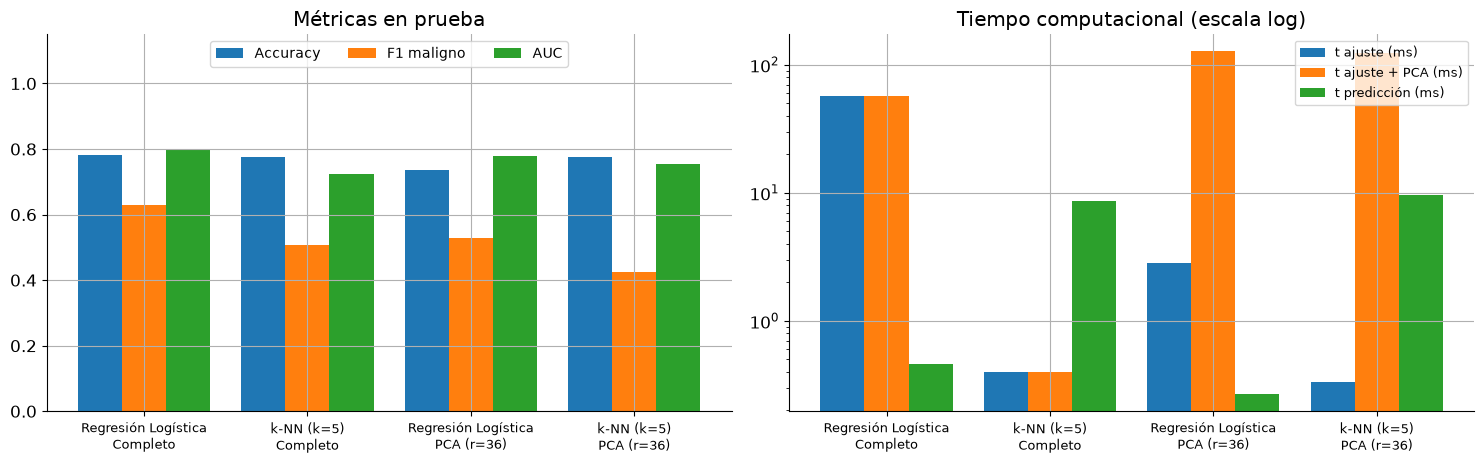

In [13]:
def medir(fn, repeticiones=7):
    # Ejecuta fn varias veces; devuelve (tiempo mínimo en s, resultado de la última ejecución)
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter(); res = fn(); tiempos.append(time.perf_counter() - t0)
    return min(tiempos), res

def base_pca(X_c, k):
    # PCA = SVD de la matriz centrada; devuelve la matriz de proyección (d, k)
    return np.linalg.svd(X_c, full_matrices=False)[2][:k].T

t_pca, Vr_t = medir(lambda: base_pca(X_train_centrado, r))
espacios = {'Completo': (X_train_vec, X_test_vec, d),
            f'PCA (r={r})': (X_train_centrado @ Vr_t, X_test_centrado @ Vr_t, r)}

filas = []
for nombre_esp, (Xtr, Xte, dim) in espacios.items():
    for nombre, modelo in crear_modelos().items():
        t_fit, est = medir(lambda: modelo.fit(Xtr, y_train))
        t_pred, y_pred = medir(lambda: est.predict(Xte))
        s_mal = puntaje_maligno(est, Xte)
        reducido = nombre_esp != 'Completo'
        filas.append({'Modelo': nombre, 'Espacio': nombre_esp, 'Dim.': dim,
                      't ajuste (ms)': t_fit * 1e3,
                      't ajuste + PCA (ms)': (t_fit + (t_pca if reducido else 0)) * 1e3,
                      't predicción (ms)': t_pred * 1e3,
                      'Accuracy': accuracy_score(y_test, y_pred),
                      'F1 maligno': f1_score(y_test, y_pred, pos_label=IDX_MAL),
                      'AUC': roc_auc_score(y_test == IDX_MAL, s_mal)})
df_comp = pd.DataFrame(filas)
print(f'Cálculo de la PCA (SVD de {n}×{d}): {t_pca * 1e3:.1f} ms\n')
print(df_comp.to_string(index=False, float_format=lambda v: f'{v:.3f}'))

# Cocientes completo / reducido (>1: el reducido es más rápido) y diferencias de métricas
print()
for nombre in df_comp['Modelo'].unique():
    a = df_comp[(df_comp['Modelo'] == nombre) & (df_comp['Espacio'] == 'Completo')].iloc[0]
    b = df_comp[(df_comp['Modelo'] == nombre) & (df_comp['Espacio'] != 'Completo')].iloc[0]
    print(f"{nombre:<20} ajuste {a['t ajuste (ms)'] / b['t ajuste (ms)']:6.2f}× | "
          f"ajuste+PCA {a['t ajuste (ms)'] / b['t ajuste + PCA (ms)']:6.2f}× | "
          f"predicción {a['t predicción (ms)'] / b['t predicción (ms)']:6.2f}× | "
          f"ΔAccuracy {b['Accuracy'] - a['Accuracy']:+.3f} | ΔF1 {b['F1 maligno'] - a['F1 maligno']:+.3f} | "
          f"ΔAUC {b['AUC'] - a['AUC']:+.3f}")
print('(× = completo / reducido, >1 significa que el reducido es más rápido; Δ = reducido − completo)')

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
etq = [f"{f['Modelo']}\n{f['Espacio']}" for _, f in df_comp.iterrows()]
x_pos = np.arange(len(df_comp))
for i, met in enumerate(['Accuracy', 'F1 maligno', 'AUC']):
    axs[0].bar(x_pos + (i - 1) * 0.27, df_comp[met], 0.27, label=met)
axs[0].set_xticks(x_pos, etq, fontsize=9); axs[0].set_ylim(0, 1.15)
axs[0].legend(ncol=3, loc='upper center', fontsize=10); axs[0].set_title('Métricas en prueba')
for i, t in enumerate(['t ajuste (ms)', 't ajuste + PCA (ms)', 't predicción (ms)']):
    axs[1].bar(x_pos + (i - 1) * 0.27, df_comp[t], 0.27, label=t)
axs[1].set_xticks(x_pos, etq, fontsize=9); axs[1].set_yscale('log')
axs[1].legend(fontsize=9); axs[1].set_title('Tiempo computacional (escala log)')
plt.tight_layout(); plt.show()

**Lectura de la comparación.**
- **Tiempo:** con $r \ll 784$, la Regresión Logística entrena más rápido porque optimiza $r+1$ parámetros en lugar de 785. El k-NN no "entrena", pero al predecir calcula distancias de cada imagen de prueba a las 546 de entrenamiento, con un costo proporcional a la dimensión. El cálculo de la PCA es un costo fijo que se paga una vez por entrenamiento. Acá se hace con la SVD completa (todas las componentes), así que puede costar más que el propio clasificador, y la columna "t ajuste + PCA" lo muestra. Ese costo se amortiza cuando se entrenan varios modelos sobre la misma proyección (como en el barrido de $r$) y se puede reducir calculando solo las $r$ primeras componentes con SVD aleatorizada (sección 1.8 de la práctica C8).
- **Métricas:** si el espacio reducido iguala o supera al completo, las $784 - r$ direcciones descartadas eran mayormente ruido. En ese caso la reducción también funciona como **regularización**, útil con tan pocas imágenes.
- **Memoria:** cada imagen pasa de 784 a $r$ números.

### Consigna Opcional (Bonus)
Implementa un clasificador que, en lugar de usar un modelo externo como Regresión Logística, utilice directamente la reconstrucción de PCA. Por ejemplo, midiendo el error de reconstrucción de una imagen de prueba usando los componentes calculados únicamente sobre imágenes benignas vs imágenes malignas.

#### Resolución del Bonus: clasificación por error de reconstrucción *(celda agregada)*
Se calcula una PCA **por clase** usando solo las imágenes de entrenamiento de esa clase (media $\mu_c$ y base $V_c$ con $k$ componentes). Una imagen de prueba $x$ se proyecta en ambos subespacios y se asigna a la clase que la reconstruye mejor:

$$\hat{c}(x) = \arg\min_c \; \| (x - \mu_c) - V_c V_c^T (x - \mu_c) \| .$$

La idea es la misma que en las *eigenfaces*: cada clase genera su propio subespacio, y una imagen debería "parecerse más" al subespacio de su clase. Como puntaje de malignidad para la Curva ROC se usa $e_{\text{normal/benigno}}(x) - e_{\text{maligno}}(x)$: cuanto mayor, más cerca está la imagen del subespacio maligno.

 k por clase  Accuracy  F1 maligno  Sensib. maligno   AUC
           1     0.737       0.594            0.714 0.771
           2     0.667       0.509            0.643 0.782
           5     0.679       0.537            0.690 0.727
          10     0.712       0.526            0.595 0.767
          20     0.744       0.512            0.500 0.745
          30     0.763       0.507            0.452 0.803
          50     0.763       0.413            0.310 0.821
          75     0.769       0.357            0.238 0.807
         100     0.782       0.393            0.262 0.827

=== Clasificador por reconstrucción — k = 100 por clase ===
accuracy = 0.782
                precision    recall  f1-score   support

       Maligno      0.786     0.262     0.393        42
Normal/Benigno      0.782     0.974     0.867       114

      accuracy                          0.782       156
     macro avg      0.784     0.618     0.630       156
  weighted avg      0.783     0.782     0.739       156



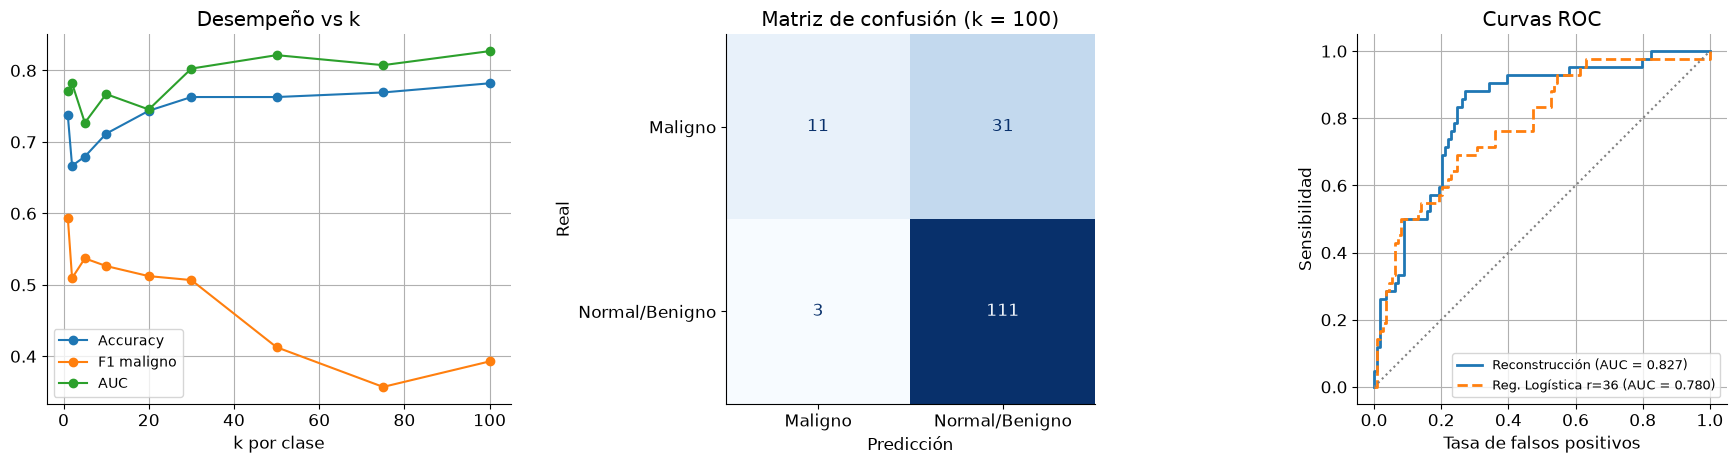

In [14]:
def ajustar_subespacios(X_vec, y, k):
    # PCA por clase: media y primeras k direcciones principales de cada clase
    sub = {}
    for c in np.unique(y):
        Xc_ = X_vec[y == c]
        mu_c = Xc_.mean(axis=0)
        Vt_c = np.linalg.svd(Xc_ - mu_c, full_matrices=False)[2]
        sub[c] = (mu_c, Vt_c[:k])
    return sub

def errores_reconstruccion(X_vec, sub):
    # Error de reconstrucción de cada imagen en el subespacio de cada clase
    err = {}
    for c, (mu_c, Vk) in sub.items():
        D = X_vec - mu_c
        err[c] = np.linalg.norm(D - (D @ Vk.T) @ Vk, axis=1)
    return err

def clasificar_por_reconstruccion(X_vec, sub):
    err = errores_reconstruccion(X_vec, sub)
    clases = np.array(sorted(err))
    y_pred = clases[np.argmin(np.vstack([err[c] for c in clases]), axis=0)]
    puntaje = err[IDX_NOMAL] - err[IDX_MAL]          # > 0 → más cerca del subespacio maligno
    return y_pred, puntaje

# Barrido de k (número de componentes por clase; la clase maligna tiene menos imágenes)
n_mal_train = np.sum(y_train == IDX_MAL)
k_bonus = [k for k in [1, 2, 5, 10, 20, 30, 50, 75, 100] if k < n_mal_train]
filas = []
for k in k_bonus:
    y_pred_b, s_b = clasificar_por_reconstruccion(X_test_vec, ajustar_subespacios(X_train_vec, y_train, k))
    filas.append({'k por clase': k, 'Accuracy': accuracy_score(y_test, y_pred_b),
                  'F1 maligno': f1_score(y_test, y_pred_b, pos_label=IDX_MAL),
                  'Sensib. maligno': recall_score(y_test, y_pred_b, pos_label=IDX_MAL),
                  'AUC': roc_auc_score(y_test == IDX_MAL, s_b)})
df_bonus = pd.DataFrame(filas)
print(df_bonus.to_string(index=False, float_format=lambda v: f'{v:.3f}'))

# Detalle con el mejor k según AUC (no depende del umbral)
k_b = int(df_bonus.loc[df_bonus['AUC'].idxmax(), 'k por clase'])
y_pred_b, s_b = clasificar_por_reconstruccion(X_test_vec, ajustar_subespacios(X_train_vec, y_train, k_b))
print(f'\n=== Clasificador por reconstrucción — k = {k_b} por clase ===')
print(f'accuracy = {accuracy_score(y_test, y_pred_b):.3f}')
print(classification_report(y_test, y_pred_b, target_names=target_names, digits=3))

fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
axs[0].plot(df_bonus['k por clase'], df_bonus['Accuracy'], 'o-', label='Accuracy')
axs[0].plot(df_bonus['k por clase'], df_bonus['F1 maligno'], 'o-', label='F1 maligno')
axs[0].plot(df_bonus['k por clase'], df_bonus['AUC'], 'o-', label='AUC')
axs[0].set_xlabel('k por clase'); axs[0].set_title('Desempeño vs k'); axs[0].legend(fontsize=10)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_b, labels=[IDX_MAL, IDX_NOMAL]),
                       display_labels=['Maligno', 'Normal/Benigno']).plot(ax=axs[1], cmap='Blues', colorbar=False)
axs[1].set_title(f'Matriz de confusión (k = {k_b})'); axs[1].grid(False)
axs[1].set_xlabel('Predicción'); axs[1].set_ylabel('Real')
fpr, tpr, _ = roc_curve(y_test == IDX_MAL, s_b)
axs[2].plot(fpr, tpr, lw=2, label=f'Reconstrucción (AUC = {roc_auc_score(y_test == IDX_MAL, s_b):.3f})')
lr = modelos_r['Regresión Logística']
fpr, tpr, _ = roc_curve(y_test == IDX_MAL, puntaje_maligno(lr, Z_test))
axs[2].plot(fpr, tpr, lw=2, ls='--', label=f'Reg. Logística r={r} (AUC = {roc_auc_score(y_test == IDX_MAL, puntaje_maligno(lr, Z_test)):.3f})')
axs[2].plot([0, 1], [0, 1], ':', color='gray')
axs[2].set_xlabel('Tasa de falsos positivos'); axs[2].set_ylabel('Sensibilidad'); axs[2].set_title('Curvas ROC')
axs[2].legend(loc='lower right', fontsize=9); axs[2].set_aspect('equal')
plt.tight_layout(); plt.show()

**Comentarios sobre el Bonus.**
- Este clasificador **no aprende una frontera de decisión**: solo modela cómo es cada clase por separado (enfoque generativo), mientras que la Regresión Logística busca directamente la combinación de componentes que separa las clases. Funciona bien si cada clase ocupa un subespacio propio; si malignas y benignas comparten casi toda su estructura (tejido, *speckle*), sus subespacios se parecen y la decisión se vuelve frágil. La comparación de AUC con la Regresión Logística (gráfico de la derecha) muestra cuál de los dos enfoques funciona mejor con estos datos.
- Funciona mejor con **pocas componentes por clase**: la primera dirección de cada subespacio ya captura el patrón típico de su clase.
- El número de componentes por clase está limitado por la clase más chica (malignas). Con $k$ grande cada subespacio reconstruye bien **cualquier** imagen, los dos errores se igualan y la decisión pierde poder.
- Las dos clases tienen distinta variabilidad: la clase normal/benigno es más heterogénea. Con un mismo $k$, los errores de reconstrucción no están en la misma escala, y eso sesga la decisión hacia una de las clases. Ajustar el umbral sobre $e_{\text{normal/benigno}} - e_{\text{maligno}}$, por ejemplo eligiéndolo en la Curva ROC, corrige parte de ese sesgo; por eso el AUC es la métrica más justa para compararlo.

## 5. Conclusiones 
La celda siguiente resume los resultados de esta ejecución; los valores se calculan en el momento, así que el texto sigue siendo correcto si cambian los datos o la semilla.

In [15]:
lr_r = df_comp[(df_comp['Modelo'] == 'Regresión Logística') & (df_comp['Espacio'] != 'Completo')].iloc[0]
lr_c = df_comp[(df_comp['Modelo'] == 'Regresión Logística') & (df_comp['Espacio'] == 'Completo')].iloc[0]
kn_r = df_comp[(df_comp['Modelo'] == 'k-NN (k=5)') & (df_comp['Espacio'] != 'Completo')].iloc[0]
kn_c = df_comp[(df_comp['Modelo'] == 'k-NN (k=5)') & (df_comp['Espacio'] == 'Completo')].iloc[0]
mejor_r = df_r.loc[df_r['F1 maligno'].idxmax()]

def comparar(nuevo, base, tol=0.01):
    return 'mejora' if nuevo > base + tol else ('empeora' if nuevo < base - tol else 'mantiene')

print(f"1. Reducción: r = {r} componentes conservan el {var_acum[r - 1]:.1%} de la varianza "
      f"({d / r:.0f}× menos dimensiones que los {d} píxeles); el codo de la curva está en k = {r_codo}.")
print(f"2. Reconstrucción con r = {r}: error relativo medio {err_tr[r - 1]:.1%} en train y {err_te[r - 1]:.1%} en test.")
print(f"3. Regresión Logística en espacio reducido: accuracy {lr_r['Accuracy']:.3f}, F1 maligno {lr_r['F1 maligno']:.3f}, "
      f"AUC {lr_r['AUC']:.3f}; frente al espacio completo {comparar(lr_r['F1 maligno'], lr_c['F1 maligno'])} el F1 "
      f"({lr_c['F1 maligno']:.3f} → {lr_r['F1 maligno']:.3f}) y entrena {lr_c['t ajuste (ms)'] / lr_r['t ajuste (ms)']:.1f}× "
      f"más rápido (sin contar la PCA).")
print(f"4. k-NN en espacio reducido: accuracy {kn_r['Accuracy']:.3f}, F1 maligno {kn_r['F1 maligno']:.3f}; "
      f"frente al completo {comparar(kn_r['F1 maligno'], kn_c['F1 maligno'])} el F1 y predice "
      f"{kn_c['t predicción (ms)'] / kn_r['t predicción (ms)']:.1f}× más rápido.")
print(f"5. Mejor combinación del barrido de r: {mejor_r['Modelo']} con r = {int(mejor_r['r'])} "
      f"(F1 maligno {mejor_r['F1 maligno']:.3f}, accuracy {mejor_r['Accuracy']:.3f}).")
print(f"6. Bonus (reconstrucción por clase, k = {k_b}): AUC {df_bonus['AUC'].max():.3f} frente a "
      f"{lr_r['AUC']:.3f} de la Regresión Logística con r = {r}.")
print(f"7. Referencia: responder siempre '{NOMBRES[IDX_NOMAL]}' da accuracy {np.mean(y_test == IDX_NOMAL):.3f} y F1 maligno 0.")

1. Reducción: r = 36 componentes conservan el 90.1% de la varianza (22× menos dimensiones que los 784 píxeles); el codo de la curva está en k = 54.
2. Reconstrucción con r = 36: error relativo medio 13.4% en train y 14.4% en test.
3. Regresión Logística en espacio reducido: accuracy 0.737, F1 maligno 0.529, AUC 0.780; frente al espacio completo empeora el F1 (0.630 → 0.529) y entrena 20.0× más rápido (sin contar la PCA).
4. k-NN en espacio reducido: accuracy 0.776, F1 maligno 0.426; frente al completo empeora el F1 y predice 0.9× más rápido.
5. Mejor combinación del barrido de r: Regresión Logística con r = 20 (F1 maligno 0.617, accuracy 0.769).
6. Bonus (reconstrucción por clase, k = 100): AUC 0.827 frente a 0.780 de la Regresión Logística con r = 36.
7. Referencia: responder siempre 'Normal/Benigno' da accuracy 0.731 y F1 maligno 0.


**Síntesis.**
- La SVD de la matriz centrada da exactamente las componentes principales: los autovalores de la covarianza son $\sigma_i^2/(n-1)$.
- Las imágenes de ecografía son redundantes (píxeles vecinos correlacionados): una fracción de las 784 dimensiones conserva el 90 % de la varianza.
- Proyectar a ese espacio reduce el costo de los clasificadores y suele mantener (o mejorar, por efecto de regularización) su desempeño.
- La máxima varianza no garantiza la máxima separación entre clases. El número de componentes que mejor clasifica no tiene por qué coincidir con el que mejor comprime, y conviene elegirlo por validación.
- En detección de cáncer, la métrica a vigilar es la **sensibilidad** de la clase maligna. Con imágenes de 28×28 y 546 ejemplos de entrenamiento el problema es difícil; resoluciones mayores de MedMNIST (`size=64`, `128` o `224` en `BreastMNIST`) o modelos no lineales son las vías naturales para mejorar.

## 6. Puntos Extra (Para repasar y profundizar a partir del material de apoyo de la clase 8)

### 6.1 Truncamiento óptimo de Gavish–Donoho 
El 90 % de varianza y el codo son criterios heurísticos. Gavish y Donoho modelan los datos como **señal de bajo rango + ruido** y demuestran que, con ruido de magnitud desconocida, el umbral óptimo para descartar valores singulares es

$$\tau = \omega(\beta)\,\sigma_{med}, \qquad \beta = \frac{\min(n,d)}{\max(n,d)},$$

donde $\sigma_{med}$ es la mediana de los valores singulares. Los $\sigma_i < \tau$ no se distinguen de los que produciría ruido puro (distribución de Marchenko–Pastur), así que conservarlos agrega ruido y no señal.

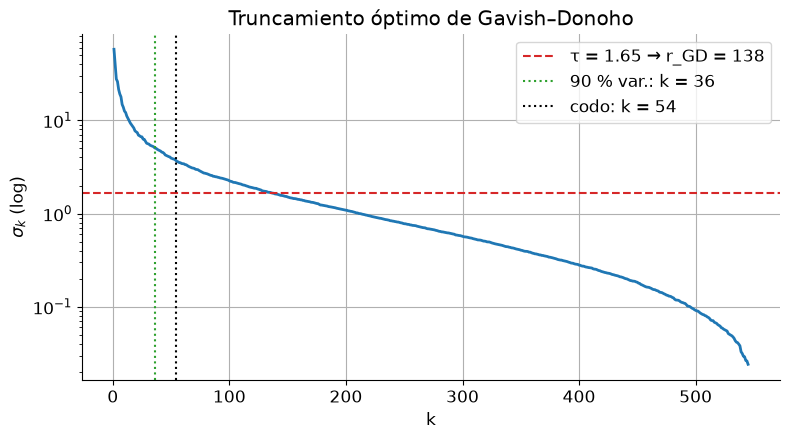

Gavish–Donoho  k = 138 (98.1% var.) | accuracy 0.712 | F1 maligno 0.536
Codo           k =  54 (93.3% var.) | accuracy 0.744 | F1 maligno 0.545
90 % varianza  k =  36 (90.1% var.) | accuracy 0.737 | F1 maligno 0.529
β = 0.696  |  ω(β) = 2.429  |  σ_med = 0.679


In [16]:
from scipy import integrate, optimize

def omega_beta(beta):
    # ω(β) = λ*(β) / √μ_β, con μ_β la mediana de Marchenko–Pastur (misma función que la práctica C8)
    lam_b = np.sqrt(2 * (beta + 1) + 8 * beta / ((beta + 1) + np.sqrt(beta**2 + 14 * beta + 1)))
    a, b = (1 - np.sqrt(beta))**2, (1 + np.sqrt(beta))**2
    f = lambda t: np.sqrt((b - t) * (t - a)) / (2 * np.pi * beta * t)
    mu = optimize.brentq(lambda m: integrate.quad(f, a, m)[0] - 0.5, a + 1e-9, b - 1e-9)
    return lam_b / np.sqrt(mu)

beta = min(n, d) / max(n, d)
S_nn = S[:r_util]                                   # se excluye el σ ≈ 0 que deja el centrado
tau = omega_beta(beta) * np.median(S_nn)
r_gd = int(np.sum(S_nn > tau))

plt.figure(figsize=(9, 4.5))
plt.semilogy(kk[:r_util], S_nn, lw=2)
plt.axhline(tau, color='C3', ls='--', label=f'τ = {tau:.2f} → r_GD = {r_gd}')
for k, nombre, color in [(r, '90 % var.', 'C2'), (r_codo, 'codo', 'k')]:
    plt.axvline(k, color=color, ls=':', label=f'{nombre}: k = {k}')
plt.xlabel('k'); plt.ylabel('$\\sigma_k$ (log)'); plt.title('Truncamiento óptimo de Gavish–Donoho')
plt.legend(); plt.show()

# Comparación de los tres criterios con la Regresión Logística
for nombre, k in [('Gavish–Donoho', r_gd), ('Codo', r_codo), ('90 % varianza', r)]:
    lr = crear_modelos()['Regresión Logística'].fit(X_train_centrado @ Vt[:k].T, y_train)
    y_p = lr.predict(X_test_centrado @ Vt[:k].T)
    print(f'{nombre:<14} k = {k:>3} ({var_acum[k - 1]:5.1%} var.) | accuracy {accuracy_score(y_test, y_p):.3f} | '
          f'F1 maligno {f1_score(y_test, y_p, pos_label=IDX_MAL):.3f}')
print(f'β = {beta:.3f}  |  ω(β) = {omega_beta(beta):.3f}  |  σ_med = {np.median(S_nn):.3f}')

### 6.2 PCA + LDA ("Fisherfaces"): máxima varianza vs máxima separación
PCA elige direcciones de **máxima varianza sin mirar las etiquetas**. El discriminante lineal de Fisher (LDA) sí usa las etiquetas: busca la dirección $w$ que maximiza

$$J(w) = \frac{(w^T(\mu_1 - \mu_0))^2}{w^T S_W\, w},$$

es decir, la separación entre las medias de clase relativa a la dispersión dentro de cada clase ($S_W$). Con $n < d$, la matriz $S_W$ de $784 \times 784$ es singular (rango $\le n-2$), así que primero se reduce con PCA a $r$ componentes y después se aplica LDA. Es el esquema clásico **Fisherfaces** (Belhumeur et al., 1997), la contraparte supervisada de las *eigenfaces*. Se compara la proyección 1D sobre la CP 1 con la proyección 1D de LDA.

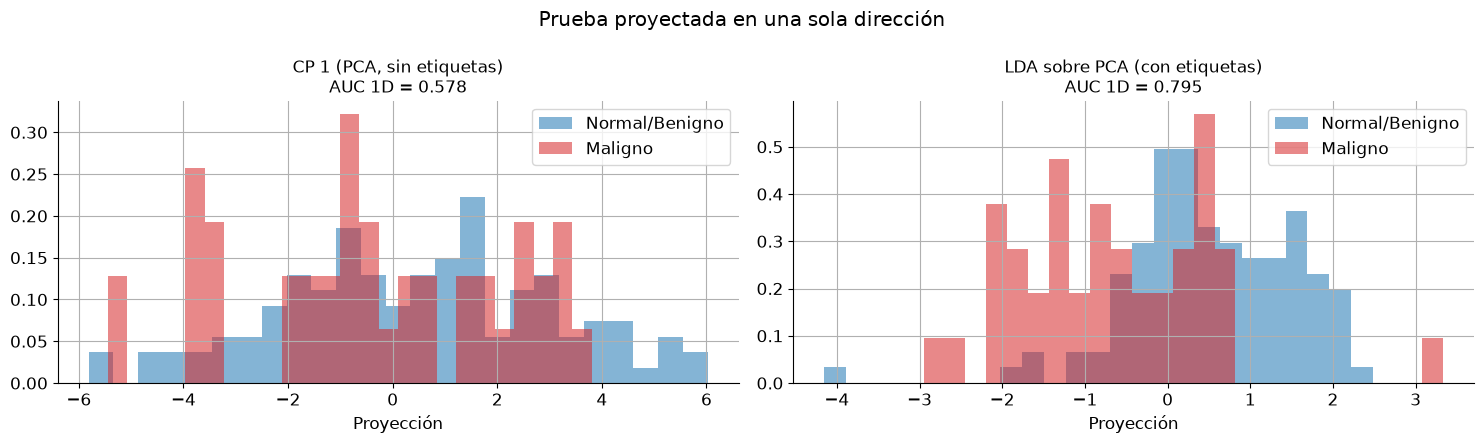

Clasificador LDA (r = 36): accuracy 0.808 | F1 maligno 0.545 | AUC 0.795


In [17]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis().fit(Z_train, y_train)      # LDA sobre las r componentes de la Consigna 4
proy = {'CP 1 (PCA, sin etiquetas)': X_test_centrado @ Vt[0],
        'LDA sobre PCA (con etiquetas)': lda.transform(Z_test).ravel()}

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (nombre, z) in zip(axs, proy.items()):
    auc = roc_auc_score(y_test == IDX_MAL, z)
    auc = max(auc, 1 - auc)                                   # el signo de cada dirección es arbitrario
    for clase, color in [(IDX_NOMAL, 'C0'), (IDX_MAL, 'C3')]:
        ax.hist(z[y_test == clase], bins=25, alpha=0.55, density=True, color=color, label=NOMBRES[clase])
    ax.set_title(f'{nombre}\nAUC 1D = {auc:.3f}', fontsize=12); ax.set_xlabel('Proyección'); ax.legend()
plt.suptitle('Prueba proyectada en una sola dirección'); plt.tight_layout(); plt.show()

y_p = lda.predict(Z_test)
print(f'Clasificador LDA (r = {r}): accuracy {accuracy_score(y_test, y_p):.3f} | '
      f'F1 maligno {f1_score(y_test, y_p, pos_label=IDX_MAL):.3f} | '
      f'AUC {roc_auc_score(y_test == IDX_MAL, lda.predict_proba(Z_test)[:, list(lda.classes_).index(IDX_MAL)]):.3f}')

### 6.3 ¿Qué píxeles usa el clasificador? Pesos de la Regresión Logística en el espacio de píxeles
La proyección PCA es lineal, así que el modelo logístico entrenado sobre $r$ componentes equivale a un modelo lineal sobre los píxeles. Con $z = V_r^T(x - \mu)$ estandarizado como $z_s = (z - m)/s$:

$$\text{logit}(x) = w^T z_s + b \;\Rightarrow\; w_{px} = V_r\,(w / s) \in \mathbb{R}^{784}.$$

Reacomodado a 28×28, $w_{px}$ muestra qué zonas empujan la decisión hacia **maligno**. Como $w_{px}$ es combinación de las $r$ eigen-imágenes, queda limitado a ese subespacio: con $r$ chico solo puede usar patrones suaves y globales, y al crecer $r$ se acerca al modelo entrenado directamente sobre los píxeles, que puede ajustarse al *speckle*. Así la PCA actúa como **regularizador espacial**, y $r$ controla cuánto.

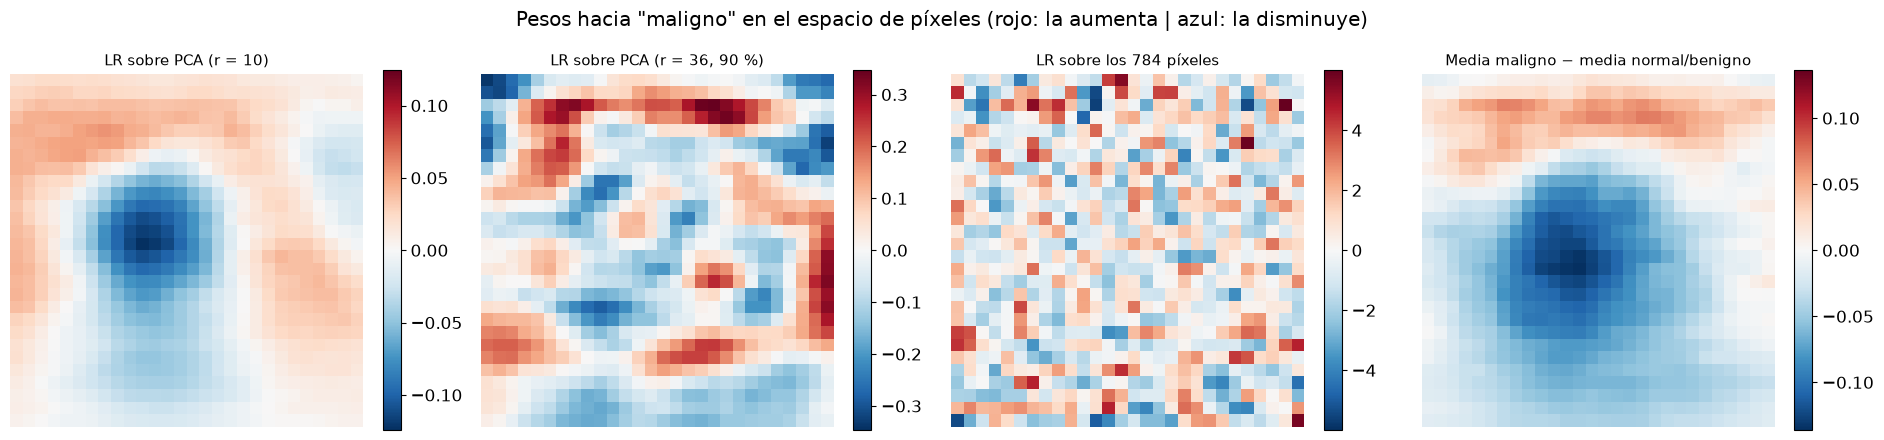

LR sobre PCA (r = 10)        correlación con la diferencia de medias: +0.794
LR sobre PCA (r = 36, 90 %)  correlación con la diferencia de medias: +0.371
LR sobre los 784 píxeles     correlación con la diferencia de medias: +0.120


In [18]:
def pesos_en_pixeles(k):
    # Entrena la LR sobre k componentes y lleva sus pesos al espacio de píxeles: w_px = V_k (w / s)
    lr = crear_modelos()['Regresión Logística'].fit(X_train_centrado @ Vt[:k].T, y_train)
    esc, clf = lr[0], lr[-1]
    signo = 1 if clf.classes_[1] == IDX_MAL else -1          # coef_ > 0 empuja hacia classes_[1]
    return signo * (Vt[:k].T @ (clf.coef_.ravel() / esc.scale_))

lr_px = crear_modelos()['Regresión Logística'].fit(X_train_vec, y_train)   # referencia sobre los 784 píxeles
signo = 1 if lr_px[-1].classes_[1] == IDX_MAL else -1
dif_medias = X_train_vec[y_train == IDX_MAL].mean(0) - X_train_vec[y_train == IDX_NOMAL].mean(0)

k_chico = min(10, r)
mapas = {f'LR sobre PCA (r = {k_chico})': pesos_en_pixeles(k_chico),
         f'LR sobre PCA (r = {r}, 90 %)': pesos_en_pixeles(r),
         'LR sobre los 784 píxeles': signo * lr_px[-1].coef_.ravel() / lr_px[0].scale_,
         'Media maligno − media normal/benigno': dif_medias}
fig, axs = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, (titulo, m) in zip(axs, mapas.items()):
    lim = np.abs(m).max()
    im = ax.imshow(m.reshape(28, 28), cmap='RdBu_r', vmin=-lim, vmax=lim)
    ax.set_title(titulo, fontsize=11); ax.axis('off'); plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle('Pesos hacia "maligno" en el espacio de píxeles (rojo: la aumenta | azul: la disminuye)')
plt.tight_layout(); plt.show()

for titulo, m in list(mapas.items())[:3]:
    print(f'{titulo:<28} correlación con la diferencia de medias: {np.corrcoef(m, dif_medias)[0, 1]:+.3f}')